### Libraries

In [1]:
import json
import os
import earthkit.data
import cdsapi
import xarray as xr
import pandas as pd
import numpy as np
import cftime
import pprint
import cdsapi
from IPython.display import display
import sys
import pickle
import matplotlib.pyplot as plt
from scipy.stats import genextreme as gev
import reverse_geocoder as rg
import folium
import math
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import plotly.io as pio
pio.renderers.default = "notebook"

### Functions

In [8]:
def coordinate_check(latitude, longitude):
    """
    Validates that the provided coordinates fall within the European domain,
    then performs a reverse‑geocoding lookup to retrieve the corresponding city and country.
    """
    if latitude >= 34.80 and latitude <= 81.8067 and longitude >= -28.8333 and longitude <= 69.0334:
        coordinates = (latitude, longitude)
        location = rg.search(coordinates)
        country = location[0]['cc']
        city = location[0]['name']
        return city, country
    else:
        raise ValueError("Climate resilience analysis is not supported in the selected region. Please select European coordinates.")

def format_coordinates(coordinate, type="latitude"):
    """
    Converts a decimal coordinate into degrees, minutes, and seconds (DMS) format,
    automatically assigning the correct directional suffix (N/S/E/W) based on value and type.
    """
    abs_degrees = abs(coordinate)
    degrees = math.floor(abs_degrees)
    minutes = math.floor(60*(abs_degrees-degrees))
    seconds = round(3600 * (abs_degrees-degrees) - 60*minutes)
    if type == "latitude":
        if coordinate < 0:
            return """{}° {}' {}" S""".format(degrees, minutes, seconds)
        else:
            return """{}° {}' {}" N""".format(degrees, minutes, seconds)
    else:
        if coordinate < 0:
            return """{}° {}' {}" W""".format(degrees, minutes, seconds)
        else:
            return """{}° {}' {}" E""".format(degrees, minutes, seconds)

def get_map(latitude, longitude, city, country):
    """
    Creates an interactive Folium map centered on the given coordinates, 
    adding a marker with a popup displaying the city, country, and formatted coordinates.
    """
    f = folium.Figure(width=500, height=500)
    m = folium.Map(location=[latitude, longitude], zoom_start=10).add_to(f)
    folium.Marker(
        location=[latitude, longitude],
        popup=folium.Popup('<b>{}, {}</b><br>({} {})'.format(city, country, format_coordinates(latitude, "latitude"), format_coordinates(longitude, "longitude")), max_width=400, min_width=80), # pop-up label for the marker
        icon=folium.Icon()
    ).add_to(m)
    return f

def download_dfs(requests, dictionay_name):
    """
    Function to "download" as a temporary file with Earthkit and add the orography/variables of several climate models to the dictionary (dfs_orography or dfs_models).
    :param requests: the parameters of the request (those indicated in the Copernicus dataset: names RCM, GCM, resolution, etc.).
    Example of a request
    irnet_orography = {
    "domain": "europe",
    "experiment": "historical",
    "horizontal_resolution": "0_11_degree_x_0_11_degree",
    "temporal_resolution": "fixed",
    "variable": ["orography"],
    "gcm_model": "ichec_ec_earth",
    "rcm_model": "knmi_racmo22e",
    "ensemble_member": "r1i1p1"
    }
    :param dictionary_name: the name of the dictionary to save the dataset in.
    """
    for key_name, request in requests:
        try:
            # "Download" the dataset and convert it into a xarray then convert the dataset into a dataframe
            ds = earthkit.data.from_source("cds", "projections-cordex-domains-single-levels", request)
            df = ds.to_xarray(xarray_open_mfdataset_kwargs=dict(decode_cf=True, decode_times=True))
            # df = ds.to_xarray(xarray_open_mfdataset_kwargs=dict(decode_cf=True, decode_times=True)).to_dataframe().reset_index()
            
            # Add to dictionary
            dictionay_name[key_name] = df
            print(f"Dataset '{key_name}' downloaded and added to dictionary")

            # Convert tasmax from Kelvin to Celsius
            if "tasmax" in df:
                df["tasmax"] = df["tasmax"] - 273.15
                df["tasmax"].attrs["units"] = "°C"
            # Convert tasmin from Kelvin to Celsius
            if "tasmin" in df:
                df["tasmin"] = df["tasmin"] - 273.15
                df["tasmin"].attrs["units"] = "°C"
            # Convert pr from kg*m-2*s-1 to mm
            if "pr" in df:
                df["pr"] = df["pr"] * 100000
                df["pr"].attrs["units"] = "mm"
            # Convertion not needed for wind speed (already in m*s-1)
    
        except Exception as e:
            print(f"Error with the dataset '{key_name}': {e}")

def run_all_models(file_json,variable):
    """
    Load climate model configurations from a JSON file, download the corresponding
    datasets for each model and time interval, and return all results in a structured
    dictionary.

    This function reads a JSON file containing multiple climate model specifications
    (GCM, RCM, ensemble member, and temporal ranges). For each model, it iterates
    through the defined start/end year pairs, builds the request parameters, and
    downloads the associated datasets using `download_dfs()`. All downloaded data
    are organized into a nested dictionary structure.

    Parameters:
        file_json (str):
            Path or filename of the JSON file containing model configurations (e.g., "tasmax.json").
        variable (str):
            Name of the climate variable to download (e.g., "maximum_2m_temperature_in_the_last_24_hours"
                                                            "minimum_2m_temperature_in_the_last_24_hours"
                                                            "mean_precipitation_flux"
                                                            "10m_wind_speed").
    Returns:
        dict:
            A dictionary where each key corresponds to a model name, and each value
            contains another dictionary mapping each temporal chunk (start_year–end_year)
            to the downloaded dataset.
    """

    dfs_models = {}                                                  # Main dictionary
    base_dir = os.getcwd()                                           # base_dir = os.getcwd() obtain current folder
    with open(os.path.join(base_dir, file_json)) as f:
        models = json.load(f)                                        # Read models from json file
    for model in models:                                             # Iterate through the models and download the data
        gcm = models[model]["gcm"]
        rcm = models[model]["rcm"]
        # ensemble_orography = models[model]["ensemble_orography"]
        ensemble_model = models[model]["ensemble_model"]
        start_years = models[model]["start_years"]
        end_years = models[model]["end_years"]
        dfs_chunks = {}                                              # Dictionary to store temporal chunks. Chunks can be: 1950-1950,1951-1955,...,1971-1975

        for sy, ey in zip(start_years, end_years):                   # Loop over each temporal chunk

            request_models = [
                (
                    f"{model}_{sy}_{ey}",
                    {
                        "domain": "europe",                                         # fixed
                        "experiment": ["historical", "rcp_4_5"],                    # change with rcp_8_5
                        "horizontal_resolution": "0_11_degree_x_0_11_degree",       # fixed
                        "temporal_resolution": "daily_mean",                        # fixed
                        "variable": variable,                                       # Argument of the function
                        "gcm_model": gcm,                                           # fixed
                        "rcm_model": rcm,                                           # fixed
                        "ensemble_member": ensemble_model,                          # fixed
                        "start_year": sy,                                           # Single start year
                        "end_year": ey,                                             # Single end year
                    },
                ),
            ]
            
            download_dfs(request_models, dfs_chunks)                  # Download of the dictionary
        dfs_models[model] = dfs_chunks                                # Fill the main dictionary
    return dfs_models

def concat_models_along_time(dfs_models):
    """
    Concatenate the temporal chunks of each model along the 'time' dimension.

    Parameters
    ----------
    dfs_models : dict
        A dictionary where each key represents a model name and each value 
        contains multiple xarray.Dataset objects corresponding to different 
        time chunks.

    Returns
    -------
    dict
        A dictionary mapping each model name to a single xarray.Dataset
        obtained by concatenating all its time chunks along the 'time' dimension.
    """
    dfs_models_concat = {}                             # Main dictionary

    for model, chunks in dfs_models.items():           # Loop over each model
        keys_sorted = sorted(chunks.keys())            # Ensure chronological order
        ds_list = [chunks[k] for k in keys_sorted]     # Extract datasets in order
        ds_concat = xr.concat(ds_list, dim="time")     # Concatenate along time
        dfs_models_concat[model] = ds_concat           # Fill the main dictionary
    return dfs_models_concat

def compute_yearly_ext(dfs_models):
    """
    Compute yearly extreme values (maximum or minimum) for each model.

    For every model dataset:
    - If 'tasmax', 'pr', and ' are present, compute the yearly maximum.
    - If 'tasmin' is present, compute the yearly minimum.

    The function resamples the data along the 'time' dimension using a
    yearly frequency ('1YE') and stores the resulting extremes in a new
    dictionary, one entry per model.
    """
    
    dfs_yearly_ext = {}                                       # Main dictionary with yearly extreme values (max or min)
    for model, ds in dfs_models.items():                      # Loop over each model
        if "tasmax" in ds:                                    # Compute yearly maximum of tasmax
            ds_yearly_ext = ds.resample(time="1YE").max()
            dfs_yearly_ext[model] = ds_yearly_ext
        if "pr" in ds:                                        # Compute yearly maximum of precipitation
            ds_yearly_ext = ds.resample(time="1YE").max()
            dfs_yearly_ext[model] = ds_yearly_ext
        if "tasmin" in ds:                                    # Compute yearly minimum of tasmin
            ds_yearly_ext = ds.resample(time="1YE").min()
            dfs_yearly_ext[model] = ds_yearly_ext
        if "sfcWind" in ds:
            ds_yearly_ext = ds.resample(time="1YE").max()     # Compute yearly maximum of wind speed
            dfs_yearly_ext[model] = ds_yearly_ext
    return dfs_yearly_ext


def split_time_windows(dfs_yearly_ext, window_length=40, shift=10):
    """
    Split yearly data into sliding time windows for each model.

    For every model dataset:
    - Extract the available years from the 'time' coordinate.
    - Generate time windows of length `window_length` years, moving forward
      by `shift` years between consecutive windows.
    - For each window, select the subset of data whose years fall within
      the window range (start_year --> end_year).
    - Store each windowed dataset in a dictionary indexed by (start_year, end_year).

    The function returns a dictionary where each model is associated with
    multiple time-window datasets, useful for analyzing long-term climate
    extremes over overlapping periods.
    """
    dfs_window = {}                                             # Main dictionary with data divided by time windows

    for model, ds in dfs_yearly_ext.items():                    # Loop over each model
        years = ds["time"].dt.year.values
        min_year, max_year = int(years.min()), int(years.max())
        windows = [
            (start, start + window_length - 1)                  # For each start (year), it generates a time window "window_length - 1" long.
            for start in range(min_year, max_year + 1, shift)
            if start + window_length - 1 <= max_year            # Exclude time windows that end beyond max_year.
        ]
        windowed_data = {}                                      # Fill the dictionary with only time windows (?)

        for start, end in windows:
            mask = (ds["time"].dt.year >= start) & (ds["time"].dt.year <= end)
            ds_window = ds.sel(time=mask)
            windowed_data[(start, end)] = ds_window
            print(f"model: {model}, window: {start}/{end}, shape: {dict(ds_window.sizes)}")
        dfs_window[model] = windowed_data

    return dfs_window

def new_ev1_param(data, T_r=50, method='LSM', value='positive'):
    original_data = data
    data = np.asarray(data).astype(float)
    p = 1 / T_r
    yp = -np.log(-np.log(1 - p))
    N = data.shape[0]
    pp = np.arange(N, 0, -1) / (N + 1)
    loglog_pp = np.log(-np.log(pp)).reshape(N, 1, 1)

    if value == 'positive':
        data_sorted = np.sort(data, axis=0)[::-1]

        if method == 'LSM':
            parmhat_2 = (
                (np.sum(data_sorted, axis=0)**2 - N * np.sum(data_sorted**2, axis=0)) /
                (N * np.sum(data_sorted * loglog_pp, axis=0)
                 - np.sum(data_sorted, axis=0) * np.sum(loglog_pp, axis=0)))
            parmhat_1 = (np.mean(data_sorted, axis=0)
                + np.sum(loglog_pp * parmhat_2, axis=0) / N)

        elif method == 'MOM':
            mean_val = np.mean(data_sorted, axis=0)
            std_val = np.std(data_sorted, ddof=1, axis=0)
            parmhat_2 = np.sqrt(6) / np.pi * std_val
            parmhat_1 = mean_val - 0.5772157 * parmhat_2


    elif value == 'negative':

        if method == 'MOM':
            data_sorted = np.sort(data, axis=0)[::-1]
            mean_val = np.mean(data_sorted, axis=0)
            std_val = np.std(data_sorted, ddof=1, axis=0)
            parmhat_2 = -np.sqrt(6) / np.pi * std_val
            parmhat_1 = mean_val - 0.5772157 * (-parmhat_2)

        elif method == 'LSM':
            data_sorted = np.sort(data, axis=0)
            parmhat_2 = ((np.sum(data_sorted, axis=0)**2 - N * np.sum(data_sorted**2, axis=0)) /
                (N * np.sum(data_sorted * loglog_pp, axis=0)
                 - np.sum(data_sorted, axis=0) * np.sum(loglog_pp, axis=0)))
            parmhat_1 = (np.mean(data_sorted, axis=0) + np.sum(loglog_pp * parmhat_2, axis=0) / N)

    R_value = parmhat_1 + parmhat_2 * yp

    new_dict = {'lat': original_data['lat'],'lon': original_data['lon'],'rlat': original_data['rlat'],'rlon': original_data['rlon']}
    new_data = xr.DataArray(data=R_value,dims=['rlat', 'rlon'],coords=new_dict)
    return new_data

def compute_window_results(dfs_window, T_r=50, variable="tasmax", method='MOM'):
    """
    Compute the temporal mean for each model and
    each defined time window.
    """
    dfs_window_means = {}
    dfs_window_cov = {}
    dfs_window_charact = {}

    positive_vars = {"tasmax", "pr", "sfcWind"}

    for model, windows in dfs_window.items():

        window_means = {}
        window_cov = {}
        window_charact = {}

        for (start, end), ds_window in windows.items():
            
            # Estrai la variabile specifica
            da_window = ds_window[variable]

            # Mean value
            window_means[(start, end)] = da_window.mean(dim="time")
            
            # COV
            window_cov[(start, end)] = (
                da_window.std(dim="time") / da_window.mean(dim="time")
            )

            # Characteristic value (EV1)
            if variable in positive_vars:
                value_type = "positive"
            elif variable == "tasmin":
                    value_type = "negative"

            window_charact[(start, end)] = new_ev1_param(
                da_window,
                T_r=T_r,
                method=method,
                value=value_type
            )

        dfs_window_means[model] = window_means
        dfs_window_cov[model] = window_cov
        dfs_window_charact[model] = window_charact

    return dfs_window_means, dfs_window_cov, dfs_window_charact


def compute_fc_from_charact(dfs_charact, variable):
    """
    Compute the factor of change (fc) from dfs_charact.

    For:
    - tasmax, tasmin: fc = difference with respect to the first time window
    - pr, sfcWind:   fc = ratio with respect to the first time window

    Parameters
    ----------
    dfs_charact : dict
        Dictionary structured as dfs_charact[model][(start, end)] = xr.DataArray
    variable: str
        Climate variable name ('tasmax', 'tasmin', 'pr', 'sfcWind')

    Returns
    -------
    dfs_fc : dict
        Dictionary with the same structure as dfs_charact containing fc values
    """

    if variable not in ["tasmax", "tasmin", "pr", "sfcWind"]:
        raise ValueError(f"Variable '{variable}' not supported for fc computation")

    dfs_fc = {}

    for model, windows in dfs_charact.items():

        sorted_windows = sorted(windows.keys(), key=lambda x: x[0])

        ref_window = sorted_windows[0]
        ref_data = windows[ref_window]

        model_fc = {}

        for window in sorted_windows:
            current_data = windows[window]

            if variable in ["tasmax", "tasmin"]:
                # difference
                fc = current_data - ref_data

            elif variable in ["pr", "sfcWind"]:
                # division
                fc = current_data / ref_data

            model_fc[window] = fc

        dfs_fc[model] = model_fc

    return dfs_fc

def extract_results(dfs_results, lat, lon):
    """
    Finds the closest (rlat,rlon) values to the given (lat, lon) for each model 
    and each available time window (period) in dfs_results. The function first converts 
    the input geographic coordinates into the corresponding model grid coordinates,
    and only after that extracts the matching dataframes.
    """
    
    coords = {}
    result_dfs = {}

    for key in dfs_results:
        coords[key] = {}
        result_dfs[key] = {}

        for period in dfs_results[key].keys():
            dfs = dfs_results[key][period]

            dist = (dfs.lat - lat)**2 + (dfs.lon - lon)**2
            idx = dist.argmin(dim=("rlat", "rlon"))

            rlat_idx = idx["rlat"]
            rlon_idx = idx["rlon"]

            rlat_value = dfs.rlat.isel(rlat=rlat_idx).item()
            rlon_value = dfs.rlon.isel(rlon=rlon_idx).item()

            coords[key] = (rlat_value, rlon_value)

            result_dfs[key][period] = dfs.sel(
                rlat=rlat_value,
                rlon=rlon_value,
                method="nearest"
            )


    return coords, result_dfs

def export_csv(dfs, label, out_filename):
    """
    Save all the data in a .csv file, and export it.
    """

    all_models = []

    for model, windows in dfs.items():
        print("Processing model:", model)

        df_model = None

        for (start, end), da in windows.items():
            da = da.compute()

            lat2d  = da["lat"].values
            lon2d  = da["lon"].values
            rlat1d = da["rlat"].values
            rlon1d = da["rlon"].values
            vals   = da.values

            nlat, nlon = vals.shape
            records = []

            for i in range(nlat):
                for j in range(nlon):
                    v = vals[i, j]
                    if np.isnan(v):
                        continue

                    records.append({
                        "lat":  float(lat2d[i, j]),
                        "lon":  float(lon2d[i, j]),
                        "rlat": float(rlat1d[i]),
                        "rlon": float(rlon1d[j]),
                        f"{label}_{start}_{end}": float(v)
                    })

            df_window = pd.DataFrame.from_records(records)

            if df_model is None:
                df_model = df_window
            else:
                df_model = df_model.merge(
                    df_window,
                    on=["lat","lon","rlat","rlon"],
                    how="outer"
                )

        df_model.insert(0, "model", model)

        all_models.append(df_model)

    final_df = pd.concat(all_models, ignore_index=True)
    final_df.to_csv(
        out_filename,
        index=False,
        sep=";",
        decimal=",",
        float_format="%.6f"
    )

    print("CSV saved:", len(final_df), "rows ->", out_filename)

### Get Coordinates

In [3]:
# Useful coordinates:
# Geographical coords of Florence:                 Lat: 43.7697,   Lon: 11.2558
# Irnet coords of Florence (nearest point):        Lat: 43.757510, Lon: 11.193669
# Irnet rotated coords of Florence:                Rlat: -6.765,   Rlon: -4.945

lat = 43.7697
lon = 11.2558

city = coordinate_check(lat,lon)
display(city)

maps = get_map(lat, lon, "Florence", "IT")
maps

Loading formatted geocoded file...


('Florence', 'IT')

### Download data tmax

In [3]:
df = run_all_models("prova_tmax.json",                                # Linked json (reduced version of json)
                    "minimum_2m_temperature_in_the_last_24_hours")    # Variable
# display(df)

2026-01-29 13:05:32,956 INFO Request ID is e879f292-18de-4e05-9056-995fdd7a53d9
2026-01-29 13:05:33,010 INFO status has been updated to accepted
2026-01-29 13:05:41,298 INFO status has been updated to running
2026-01-29 13:05:46,402 INFO status has been updated to successful


456c655083b1d65ff751f5d0f7800f47.zip:   0%|          | 0.00/85.5M [00:00<?, ?B/s]

  0%|          | 0/1 [00:00<?, ?it/s]

Dataset 'irnet_1950_1950' downloaded and added to dictionary


2026-01-29 13:06:00,748 INFO Request ID is 9d37c313-1085-41b9-a4c4-655ed62edccb
2026-01-29 13:06:00,791 INFO status has been updated to accepted
2026-01-29 13:06:14,328 INFO status has been updated to successful


f6b893476b8311be1abb6f3bd11ce7da.zip:   0%|          | 0.00/421M [00:00<?, ?B/s]

... (6 outputs left out)

2026-01-29 13:07:21,498 INFO Request ID is 7c7721eb-5fb1-4dd4-aa74-d25e6273df28
2026-01-29 13:07:21,547 INFO status has been updated to accepted
2026-01-29 13:07:37,403 INFO status has been updated to running
2026-01-29 13:07:45,025 INFO status has been updated to successful


fee4ff3d2e6142d104f2e71e5b0b2f75.zip:   0%|          | 0.00/419M [00:00<?, ?B/s]

  0%|          | 0/1 [00:00<?, ?it/s]

Dataset 'uknet_1951_1955' downloaded and added to dictionary


### Processing Data

In [4]:
dfs_concat = concat_models_along_time(df)

# If you want to display dataframe (converted from xarray):
# dataframe_concat = dfs_concat["irnet"].tasmax.sel(
#         rlat= -6.765,
#         rlon= -4.945,
#         method = "nearest"
# )
# print(dataframe_concat)
# # dataframe_concat.values
# # dataframe_concat.to_dataframe() :lowest
# dataframe_yearly.compute()

In [5]:
dfs_yearly = compute_yearly_ext(dfs_concat)

# dataframe_yearly = dfs_yearly["irnet"].tasmax.sel(
#         rlat= -6.765,
#         rlon= -4.945,
#         method = "nearest"
# )
# print(dataframe_yearly)
# # # dataframe_yearly.values
# dataframe_yearly.to_dataframe()

In [6]:
dfs_window = split_time_windows(dfs_yearly, window_length=4, shift=2)

model: irnet, window: 1950/1953, shape: {'time': 4, 'bnds': 2, 'rlat': 412, 'rlon': 424}
model: irnet, window: 1952/1955, shape: {'time': 4, 'bnds': 2, 'rlat': 412, 'rlon': 424}
model: uknet, window: 1950/1953, shape: {'time': 4, 'bnds': 2, 'rlat': 412, 'rlon': 424}
model: uknet, window: 1952/1955, shape: {'time': 4, 'bnds': 2, 'rlat': 412, 'rlon': 424}


In [15]:
dfs_means, dfs_cov, dfs_charact = compute_window_results(dfs_window, T_r=50, variable="tasmin", method='LSM')

# periodo = (1952,1955)

# dataframe_charact = dfs_charact["irnet"][periodo].sel(
#     rlat= -28,
#     rlon= -34,
#     method = "nearest"
# )

# print(dataframe_charact)
# dataframe_charact.values

<xarray.DataArray ()> Size: 8B
array(-2.7972842)
Coordinates:
    lat      float64 8B 21.99
    lon      float64 8B -10.06
    rlat     float64 8B -23.38
    rlon     float64 8B -28.38


array(-2.7972842)

In [ ]:
dfs_fc = compute_fc_from_charact(dfs_charact, variable="tasmax")

In [52]:
# coords, means = extract_results(dfs_means, lat, lon)

# period = (1950,1953)
# result = means["irnet"][period]
# print(result.values)
# print(coords)

In [141]:
export_csv(dfs_charact, "charact", "tasmax_charact_MOM.csv")
# export_csv(dfs_fc, "fc", "tasmax_fc_MOM.csv")

Processing model: irnet
Processing model: uknet
CSV saved: 349376 rows -> tasmax_charact_MOM.csv


### Plot each model separately

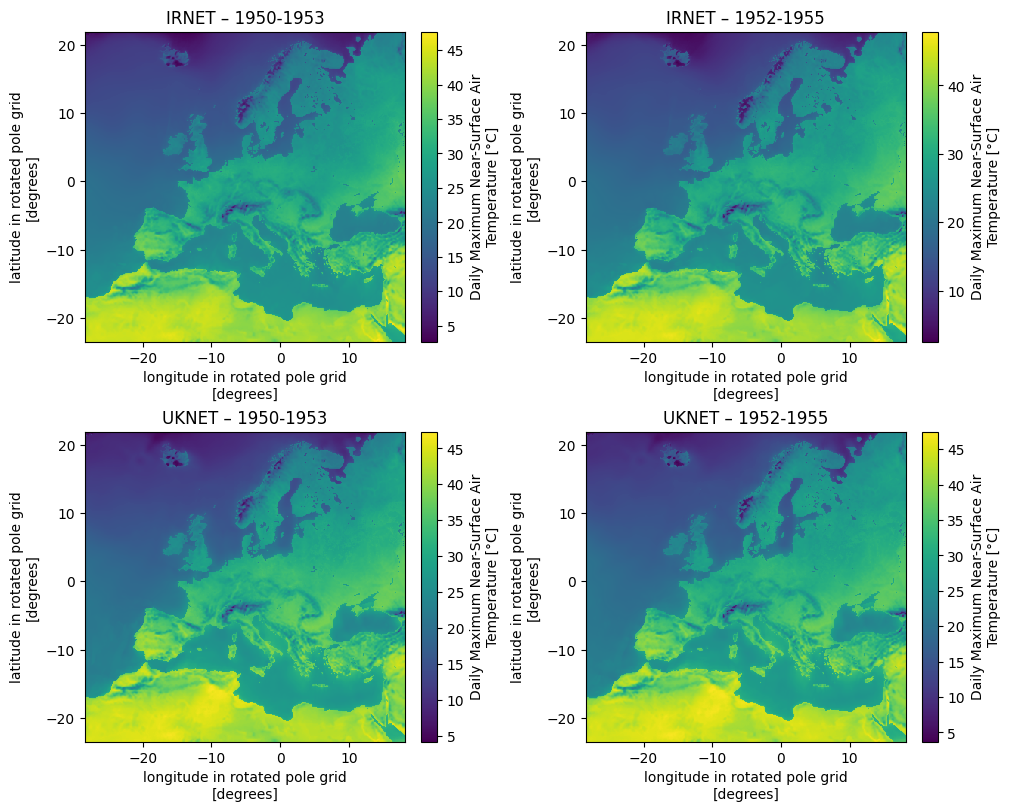

In [10]:
# models = list(dfs_means.keys())
# periods = list(next(iter(dfs_means.values())).keys())

# n_rows = len(models)
# n_cols = len(periods)

# fig, axes = plt.subplots(n_rows, n_cols, figsize=(5*n_cols, 4*n_rows), constrained_layout=True)

# if n_rows == 1:
#     axes = axes[None, :]
# if n_cols == 1:
#     axes = axes[:, None]

# for i, model in enumerate(models):
#     for j, period in enumerate(periods):
#         da = dfs_means[model][period]
#         ax = axes[i, j]
#         da.plot(ax=ax)
#         ax.set_title(f"{model.upper()} – {period[0]}-{period[1]}")

# plt.show()

In [ ]:
# fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# dfs_yearly["irnet"].tasmax.isel(time=0).plot(ax=axes[0])
# axes[0].set_title("IRNET – tasmax")

# dfs_yearly["uknet"].tasmax.isel(time=0).plot(ax=axes[1])
# axes[1].set_title("UKNET – tasmax")

# plt.tight_layout()
# plt.show()

### Dynamic Plot using Plotly

In [89]:
# One model and one period
model = "irnet"
period = (1950, 1953)
da = dfs_means[model][period]
font = "Arial"

colorscale = [
    [0.0, "rgb(49,54,149)"],
    [0.1111111111111111, "rgb(69,117,180)"],
    [0.2222222222222222, "rgb(116,173,209)"],
    [0.3333333333333333, "rgb(171,217,233)"],
    [0.4444444444444444, "rgb(224,243,248)"],
    [0.5555555555555556, "rgb(254,224,144)"],
    [0.6666666666666666, "rgb(253,174,97)"],
    [0.7777777777777778, "rgb(244,109,67)"],
    [0.8888888888888888, "rgb(215,48,39)"],
    [1.0, "rgb(165,0,38)"]
]


fig = go.Figure(
    data=go.Heatmap(z=da.values,
                    x=da.rlon.values,
                    y=da.rlat.values,
                    colorscale = colorscale,
                    colorbar=dict(title=dict(text=da.name,font=dict(family = font, size=14)),
                                  tickfont=dict(family = font, size=12))))

fig.update_layout(
    width=1000,
    height=800,

    # font=dict(family = font,size=14),

    title=dict(                                             # Title
        text=f"{model.upper()},{period[0]}–{period[1]}",
        x=0.5,
        xanchor="center",
        font=dict(family=f"{font}, Bold", size=20, color="black")),
    xaxis=dict(
        title=dict(text="Longitude",font=dict(family = font, size=16)),
        showgrid=False,
        zeroline=False),
    yaxis=dict(
        title=dict(text="Latitude",font=dict(family = font, size=16)),
        showgrid=True,
        zeroline=False),

    margin=dict(l=20, r=20, t=40, b=20)
)

fig.show()


In [ ]:
# All models and periods

# Input
models = list(dfs_means.keys())
periods = list(next(iter(dfs_means.values())).keys())

n_rows = len(models)
n_cols = len(periods)

font = "Arial"

colorscale = [
    [0.0, "rgb(49,54,149)"],
    [0.1111111111111111, "rgb(69,117,180)"],
    [0.2222222222222222, "rgb(116,173,209)"],
    [0.3333333333333333, "rgb(171,217,233)"],
    [0.4444444444444444, "rgb(224,243,248)"],
    [0.5555555555555556, "rgb(254,224,144)"],
    [0.6666666666666666, "rgb(253,174,97)"],
    [0.7777777777777778, "rgb(244,109,67)"],
    [0.8888888888888888, "rgb(215,48,39)"],
    [1.0, "rgb(165,0,38)"]
]

# Subplot
fig = make_subplots(
    rows=n_rows,
    cols=n_cols,
    subplot_titles=[
        f"{model.upper()}: {period[0]}–{period[1]}"
        for model in models
        for period in periods
    ],
    horizontal_spacing=0.1,
    vertical_spacing=0.15
)

# Heatmaps
for i, model in enumerate(models):
    for j, period in enumerate(periods):

        da = dfs_means[model][period]

        fig.add_trace(
            go.Heatmap(
                z=da.values,
                x=da.rlon.values,
                y=da.rlat.values,
                colorscale=colorscale,
                showscale=(i == 0 and j == n_cols - 1),
                colorbar=dict(
                    title=dict(text=da.name,font=dict(family=font, size=14)),
                    tickfont=dict(family=font, size=12))),
            row=i + 1,col=j + 1)
        fig.update_xaxes(
            title_text="Longitude" if i == n_rows - 1 else "",
            showgrid=False,zeroline=False,row=i + 1,col=j + 1)
        fig.update_yaxes(
            title_text="Latitude" if j == 0 else "",
            showgrid=True,zeroline=False,row=i + 1,col=j + 1)

# Layout
fig.update_layout(
    width=350 * n_cols,
    height=300 * n_rows,
    font=dict(family=font, size=14),
    title=dict(
        text="Climate Change: Trends of Maximum Temperature in Europe",
        x=0.5,
        xanchor="center",
        font=dict(family=f"{font}, Bold", size=22)),
    margin=dict(l=80, r=80, t=80, b=80))

fig.show()